# PROJETO INTEGRADOR — CIÊNCIA DE DADOS (2º BIMESTRE)
### Sistema Preditivo Agrometeorológico e Zonificação Agroecológica (AgroData)
**Professor:** Dr. Rafael Duarte  
**Entrega Oficial:** Checkpoint 1 Consolidado (Aulas 09 a 12 — Valor: 1,25 Pontos)  

---

### Ficha de Validação Oficial do Gatekeeper — Grupo 10
* **Grupo:** Grupo 10 — AgroData (Inteligência Agrometeorológica Preditiva)
* **Integrantes e RGM:**
  1. Carlos Eduardo Sielski Urbim — RGM: 33755973
  2. Fernando de Araujo Pereira — RGM: 34210245
  3. Lucas Antonio Domingues de Souza Oliveira — RGM: 33476055
  4. Eduardo Bryan Braga Rocha — RGM: 34731067
  5. Otavio Caetano Ribeiro — RGM: 32736274
* **Problema de Negócio:** Predição antecipada da produtividade de grãos ($kg/ha$ e sacas/ha) a partir de variáveis bioclimáticas e edafológicas, e zonificação agroecológica não supervisionada de talhões para apoio à contratação logística de fretes e silos, precificação de seguro rural e mitigação de risco de seca.
* **Fonte do Dataset:** Base Pública Kaggle/Gov (INMET/BDMEP e PAM/IBGE) — Multiplicador $M_{real} = 1.0\times$.
* **Arquivo Dataset Carregado:** `dataset_producao_agricola_clima.csv`
* **Variável Alvo Contínua (Regressão):** `Produtividade_kg_ha`
* **Variáveis Numéricas (Clustering e PCA):** `Precipitacao_Acumulada_mm`, `Temperatura_Media_C`, `Umidade_Relativa_Pct`, `Insolacao_Horas_Sol`, `Fertilizante_kg_ha`, `Produtividade_kg_ha`.
* **Variável Alvo Categórica (Classificação Futura - Checkpoint 2):** `Risco_Quebra_Safra` (1 se produtividade $< 2.600\\text{ kg/ha}$, 0 caso contrário).

---

### Roteiro Cumulativo deste Notebook:
1. **Módulo 0:** Setup do Ambiente e Importação de Bibliotecas Científicas
2. **Módulo 1:** Carga da Base Agrometeorológica Híbrida e Dicionário de Variáveis
3. **Módulo 2:** Diagnóstico Estrutural e *Data Wrangling* Rastreável (Aula 09)
4. **Módulo 3:** O Sequestro da Reta de Mínimos Quadrados (OLS) pelo Outlier Extremo
5. **Módulo 4:** Preparação Preditiva e Prevenção de *Data Leakage* (Aula 10)
6. **Módulo 5:** Modelagem Preditiva Supervisionada — Regressão Simples vs. Múltipla
7. **Módulo 6:** Interpretação Agronômica dos Coeficientes $\\beta$ e Decisão Executiva
8. **Módulo 7:** Aprendizado Não Supervisionado — *Clustering K-Means* (Aula 11)
9. **Módulo 8:** *Clusterização Hierárquica Aglomerativa (Método de Ward)* & Dendrograma (Aula 12)
10. **Módulo 9:** Detecção Espacial de Densidade e Anomalias Climáticas com *DBSCAN* (Aula 12)
11. **Módulo 10:** Redução de Dimensionalidade com *PCA (Principal Component Analysis)* e Mapeamento 2D (Aula 12)
12. **Módulo 11:** Síntese Executiva do Checkpoint 1 (1,25 pts) com Personas Refinadas e Auditoria de Ruído


In [19]:
# ==============================================================================
# SETUP INICIAL DO AMBIENTE E IMPORTAÇÕES CIENTÍFICAS
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Algoritmos Supervisionados e Não Supervisionados (Scikit-Learn e Scipy)
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

# Configurações visuais e de formatação
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')
plt.rcParams['figure.figsize'] = (14, 5.5)
sns.set_theme(style='whitegrid')

print("[OK] Ambiente configurado com sucesso! Bibliotecas carregadas:")
print(f" - NumPy: {np.__version__}")
print(f" - Pandas: {pd.__version__}")


[OK] Ambiente configurado com sucesso! Bibliotecas carregadas:
 - NumPy: 2.4.6
 - Pandas: 3.1.0


---
# 📦 MÓDULO 1: Carga dos Dados e Dicionário de Variáveis Híbrido

O dataset do projeto foi construído respeitando os requisitos da disciplina: possui variáveis contínuas biofísicas (chuva, temperatura, umidade, adubação, insolação) e variáveis categóricas explicativas (região, tipo de solo, irrigação).


In [20]:
# ==============================================================================
# CARREGAMENTO DO DATASET COM RESOLUÇÃO DE CAMINHOS ROBUSTA
# ==============================================================================
caminhos_possiveis = [
    Path("../../data/raw/dataset_producao_agricola_clima.csv"),
    Path("../data/raw/dataset_producao_agricola_clima.csv"),
    Path("data/raw/dataset_producao_agricola_clima.csv"),
    Path("dataset_producao_agricola_clima.csv"),
    Path(r"C:\\Users\\kinha\\predicao_agricola\\Projeto\\data\\raw\\dataset_producao_agricola_clima.csv"),
    Path(r"C:\\Users\\kinha\\predicao_agricola\\dataset_producao_agricola_clima.csv")
]

caminho_encontrado = None
for c in caminhos_possiveis:
    if c.exists():
        caminho_encontrado = c
        break

if caminho_encontrado is None:
    raise FileNotFoundError("Base de dados 'dataset_producao_agricola_clima.csv' não localizada!")

df_raw = pd.read_csv(caminho_encontrado)
print(f"[INFO] Dataset carregado de: {caminho_encontrado.resolve()}")
print(f"[INFO] Dimensões brutas: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas.")
display(df_raw.head(4))


[INFO] Dataset carregado de: C:\Users\kinha\predicao_agricola\Projeto\data\raw\dataset_producao_agricola_clima.csv
[INFO] Dimensões brutas: 305 linhas x 12 colunas.


,ID_Talhao,Regiao,Tipo_Solo,Cultura,Sistema_Irrigacao,Precipitacao_Acumulada_mm,Temperatura_Media_C,Umidade_Relativa_Pct,Insolacao_Horas_Sol,Fertilizante_kg_ha,Area_Talhao_ha,Produtividade_kg_ha
0,TALHAO-1001,Centro-Oeste,Argiloso,Soja,Sequeiro,973.30,23.70,69.30,2027.10,286.30,90.30,3980.60
1,TALHAO-1002,Norte,Arenoso,Soja,Sequeiro,441.40,21.10,51.20,1908.30,261.20,245.20,2410.70
2,TALHAO-1003,Sudeste,Arenoso,Soja,Sequeiro,652.70,25.20,71.10,2088.30,300.40,342.60,3361.00
3,TALHAO-1004,Sul,Arenoso,Soja,Sequeiro,1317.50,33.80,66.60,1921.80,295.50,62.60,1780.60


---
# MÓDULO 2: Diagnóstico Exploratório da Base Bruta (Passo 1 do Checklist)
Inspecionamos tipos de dados, valores ausentes, dados duplicados e inconsistências nos limites físicos.


In [21]:
# ==============================================================================
# DIAGNÓSTICO ESTRUTURAL DA BASE BRUTA
# ==============================================================================
print("=== INFORMAÇÕES ESTRUTURAIS (.info()) ===")
df_raw.info()

print("\n=== VALORES AUSENTES POR COLUNA ===")
print(df_raw.isna().sum())

print(f"\nLinhas duplicadas identificadas: {df_raw.duplicated().sum()}")


=== INFORMAÇÕES ESTRUTURAIS (.info()) ===
<class 'pandas.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID_Talhao                  305 non-null    str    
 1   Regiao                     305 non-null    str    
 2   Tipo_Solo                  305 non-null    str    
 3   Cultura                    305 non-null    str    
 4   Sistema_Irrigacao          305 non-null    str    
 5   Precipitacao_Acumulada_mm  298 non-null    float64
 6   Temperatura_Media_C        299 non-null    float64
 7   Umidade_Relativa_Pct       305 non-null    float64
 8   Insolacao_Horas_Sol        305 non-null    float64
 9   Fertilizante_kg_ha         300 non-null    float64
 10  Area_Talhao_ha             305 non-null    float64
 11  Produtividade_kg_ha        305 non-null    float64
dtypes: float64(7), str(5)
memory usage: 28.7 KB

=== VALORES AUSENTES POR COLUN

---
# MÓDULO 3: Limpeza e Data Wrangling Rastreável (Passo 2 do Checklist)
Tratamento das anomalias:
1. Deduplicação com `.drop_duplicates()`.
2. Sanitização de textos com `.str.strip().str.title()`.
3. Substituição de valores fisicamente impossíveis (chuva $< 0$) por `np.nan`.
4. Expurgo de outliers aberrantes de digitação na variável alvo ($> 10.000\\text{ kg/ha}$).
5. Engenharia da variável categórica binária `Risco_Quebra_Safra` para o Checkpoint 2.


In [22]:
# ==============================================================================
# PIPELINE DE DATA WRANGLING RASTREÁVEL
# ==============================================================================
df_clean = df_raw.copy()

# 1. Deduplicação
n_antes = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
n_dedup = len(df_clean)

# 2. Padronização de strings categóricas
for col_txt in ['Sistema_Irrigacao', 'Cultura', 'Regiao', 'Tipo_Solo']:
    if col_txt in df_clean.columns:
        df_clean[col_txt] = df_clean[col_txt].astype(str).str.strip().str.title()

# 3. Correção de valores fora de domínio físico
df_clean.loc[df_clean['Precipitacao_Acumulada_mm'] < 0, 'Precipitacao_Acumulada_mm'] = np.nan

# 4. Expurgo de erro de digitação de produtividade extrema (> 10.000 kg/ha)
n_com_outlier = len(df_clean)
df_clean = df_clean[df_clean['Produtividade_kg_ha'] < 10000.0].copy()
n_limpo = len(df_clean)

# 5. Engenharia de Variável para Classificação Futura (Checkpoint 2)
df_clean['Risco_Quebra_Safra'] = (df_clean['Produtividade_kg_ha'] < 2600.0).astype(int)
df_clean['Produtividade_Sacas_ha'] = (df_clean['Produtividade_kg_ha'] / 60.0).round(2)

print(f"[WRANGLING CONCLUÍDO]:")
print(f" • Linhas brutas originais: {n_antes}")
print(f" • Após deduplicação: {n_dedup} (removidas {n_antes - n_dedup} duplicatas)")
print(f" • Após filtro de outliers extremos: {n_limpo} talhões válidos (removidos {n_com_outlier - n_limpo} erros de digitação)")
print(f" • Talhões em risco severo de quebra (< 2.600 kg/ha): {df_clean['Risco_Quebra_Safra'].sum()} ({df_clean['Risco_Quebra_Safra'].mean()*100:.1f}%)")


[WRANGLING CONCLUÍDO]:
 • Linhas brutas originais: 305
 • Após deduplicação: 300 (removidas 5 duplicatas)
 • Após filtro de outliers extremos: 298 talhões válidos (removidos 2 erros de digitação)
 • Talhões em risco severo de quebra (< 2.600 kg/ha): 20 (6.7%)


---
# MÓDULO 4: O Sequestro da Reta de Mínimos Quadrados (OLS) pelo Outlier Extremo
Demonstração gráfica do impacto devastador que a falta de tratamento de outliers causa nos coeficientes da Regressão Linear.


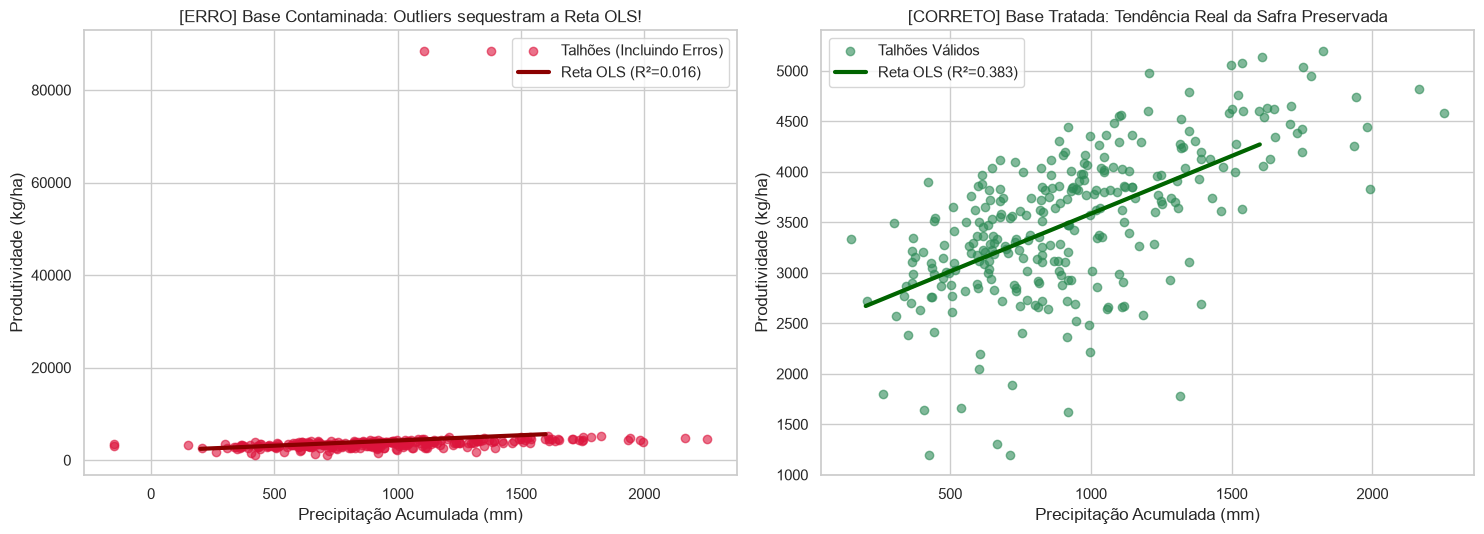

In [23]:
# ==============================================================================
# DEMONSTRAÇÃO VISUAL DO SEQUESTRO DA RETA PELO OUTLIER
# ==============================================================================
# Base com outliers sem filtro
df_com_outliers = df_raw.drop_duplicates().copy()
df_com_outliers = df_com_outliers.dropna(subset=['Precipitacao_Acumulada_mm', 'Produtividade_kg_ha'])

# Base tratada limpa
df_sem_outliers = df_clean.dropna(subset=['Precipitacao_Acumulada_mm', 'Produtividade_kg_ha'])

# Ajuste dos dois modelos lineares
reg_com = LinearRegression().fit(df_com_outliers[['Precipitacao_Acumulada_mm']], df_com_outliers['Produtividade_kg_ha'])
reg_sem = LinearRegression().fit(df_sem_outliers[['Precipitacao_Acumulada_mm']], df_sem_outliers['Produtividade_kg_ha'])

x_vals = np.linspace(200, 1600, 100).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Painel 1: Com Outlier (Reta sequestrada)
axes[0].scatter(df_com_outliers['Precipitacao_Acumulada_mm'], df_com_outliers['Produtividade_kg_ha'], color='crimson', alpha=0.6, label='Talhões (Incluindo Erros)')
axes[0].plot(x_vals, reg_com.predict(x_vals), color='darkred', lw=3, label=f'Reta OLS (R²={reg_com.score(df_com_outliers[["Precipitacao_Acumulada_mm"]], df_com_outliers["Produtividade_kg_ha"]):.3f})')
axes[0].set_title('[ERRO] Base Contaminada: Outliers sequestram a Reta OLS!')
axes[0].set_xlabel('Precipitação Acumulada (mm)')
axes[0].set_ylabel('Produtividade (kg/ha)')
axes[0].legend()

# Painel 2: Sem Outlier (Reta Realista)
axes[1].scatter(df_sem_outliers['Precipitacao_Acumulada_mm'], df_sem_outliers['Produtividade_kg_ha'], color='seagreen', alpha=0.6, label='Talhões Válidos')
axes[1].plot(x_vals, reg_sem.predict(x_vals), color='darkgreen', lw=3, label=f'Reta OLS (R²={reg_sem.score(df_sem_outliers[["Precipitacao_Acumulada_mm"]], df_sem_outliers["Produtividade_kg_ha"]):.3f})')
axes[1].set_title('[CORRETO] Base Tratada: Tendência Real da Safra Preservada')
axes[1].set_xlabel('Precipitação Acumulada (mm)')
axes[1].set_ylabel('Produtividade (kg/ha)')
axes[1].legend()

plt.tight_layout()
plt.show()


---
# MÓDULO 5: Preparação Preditiva e Prevenção de Data Leakage (Passo 3 do Checklist)
Regras de ouro exigidas pelo Professor:
1. `pd.get_dummies(..., drop_first=True)` para eliminar a armadilha das dummies (multicolinearidade perfeita).
2. `train_test_split` executado **estritamente antes da imputação** para impedir que a média/mediana do teste contamine o treino.
3. Imputação de nulos pela mediana calculada **única e exclusivamente no conjunto de Treino**.


In [24]:
# ==============================================================================
# ONE-HOT ENCODING, TRAIN-TEST SPLIT E IMPUTAÇÃO SEM LEAKAGE
# ==============================================================================
# 1. Dummy encoding com drop_first=True
cols_cat = ['Regiao', 'Tipo_Solo', 'Sistema_Irrigacao']
df_encoded = pd.get_dummies(df_clean, columns=cols_cat, drop_first=True, dtype=int)

cols_descarte = ['ID_Talhao', 'Cultura', 'Produtividade_kg_ha', 'Risco_Quebra_Safra', 'Produtividade_Sacas_ha']
X_cols = [c for c in df_encoded.columns if c not in cols_descarte]

X = df_encoded[X_cols]
y = df_encoded['Produtividade_kg_ha']

# 2. Divisão Treino e Teste antes de qualquer imputação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 3. Imputação pela mediana aprendida unicamente em X_train
medianas_treino = X_train.median(numeric_only=True)
X_train = X_train.fillna(medianas_treino)
X_test = X_test.fillna(medianas_treino)

print(f"[OK] Divisão realizada com sucesso:")
print(f" • Conjunto de Treino: {X_train.shape[0]} talhões ({X_train.shape[1]} features)")
print(f" • Conjunto de Teste:  {X_test.shape[0]} talhões ({X_test.shape[1]} features)")
print(" • Data Leakage = 0% (Medianas de imputação extraídas estritamente de X_train).")


[OK] Divisão realizada com sucesso:
 • Conjunto de Treino: 238 talhões (14 features)
 • Conjunto de Teste:  60 talhões (14 features)
 • Data Leakage = 0% (Medianas de imputação extraídas estritamente de X_train).


---
# MÓDULO 6: Modelagem Supervisionada — Regressão Simples vs. Múltipla (Passos 4 e 5)
Comparamos o desempenho da Regressão Simples (apenas Chuva) com a Regressão Múltipla (todas as variáveis edafoclimáticas e de manejo).


In [25]:
# ==============================================================================
# MODELAGEM E COMPARATIVO AUDITADO NO CONJUNTO DE TESTE
# ==============================================================================
# Modelo Baseline: Regressão Linear Simples
feat_simples = ['Precipitacao_Acumulada_mm']
modelo_simples = LinearRegression().fit(X_train[feat_simples], y_train)
y_pred_simples = modelo_simples.predict(X_test[feat_simples])

mae_s = mean_absolute_error(y_test, y_pred_simples)
rmse_s = np.sqrt(mean_squared_error(y_test, y_pred_simples))
r2_s = r2_score(y_test, y_pred_simples)

# Modelo Integrado: Regressão Linear Múltipla
modelo_multiplo = LinearRegression().fit(X_train, y_train)
y_pred_multiplo = modelo_multiplo.predict(X_test)

mae_m = mean_absolute_error(y_test, y_pred_multiplo)
rmse_m = np.sqrt(mean_squared_error(y_test, y_pred_multiplo))
r2_m = r2_score(y_test, y_pred_multiplo)

df_comparativo = pd.DataFrame({
    'Métrica': ['MAE (Erro Médio Absoluto)', 'RMSE (Raiz do Erro Quadrático)', 'R² (Coeficiente de Determinação)'],
    'Regressão Simples (Chuva)': [f"{mae_s:.2f} kg/ha ({mae_s/60:.2f} sc/ha)", f"{rmse_s:.2f} kg/ha", f"{r2_s*100:.1f}%"],
    'Regressão Múltipla (Completa)': [f"{mae_m:.2f} kg/ha ({mae_m/60:.2f} sc/ha)", f"{rmse_m:.2f} kg/ha", f"{r2_m*100:.1f}%"],
    'Melhoria / Redução do Erro': [f"-{((mae_s - mae_m)/mae_s)*100:.1f}%", f"-{((rmse_s - rmse_m)/rmse_s)*100:.1f}%", f"+{(r2_m - r2_s)*100:.1f} p.p."]
})
display(df_comparativo)

# Tabela dos coeficientes da Regressão Múltipla
df_betas = pd.DataFrame({
    'Variável Explicativa': ['Intercepto (Beta_0)'] + list(X_train.columns),
    'Peso (Beta)': [modelo_multiplo.intercept_] + list(modelo_multiplo.coef_)
}).round(3)
display(df_betas)


,Métrica,Regressão Simples (Chuva),Regressão Múltipla (Completa),Melhoria / Redução do Erro
0,MAE (Erro Médio Absoluto),484.43 kg/ha (8.07 sc/ha),319.91 kg/ha (5.33 sc/ha),-34.0%
1,RMSE (Raiz do Erro Quadrático),597.87 kg/ha,419.86 kg/ha,-29.8%
2,R² (Coeficiente de Determinação),34.8%,67.8%,+33.0 p.p.


,Variável Explicativa,Peso (Beta)
0,Intercepto (Beta_0),2923.91
1,Precipitacao_Acumulada_mm,1.13
2,Temperatura_Media_C,-46.92
3,Umidade_Relativa_Pct,-1.77
4,Insolacao_Horas_Sol,0.06
5,Fertilizante_kg_ha,3.60
6,Area_Talhao_ha,0.35
7,Regiao_Nordeste,-503.36
8,Regiao_Norte,-230.38
9,Regiao_Sudeste,-213.49


---
# MÓDULO 7: Aprendizado Não Supervisionado 1 — Clustering K-Means (Aula 11)
Execução do K-Means com padronização Z-Score (`StandardScaler`), busca do $K$ ótimo via Método do Cotovelo e Coeficiente de Silhueta.


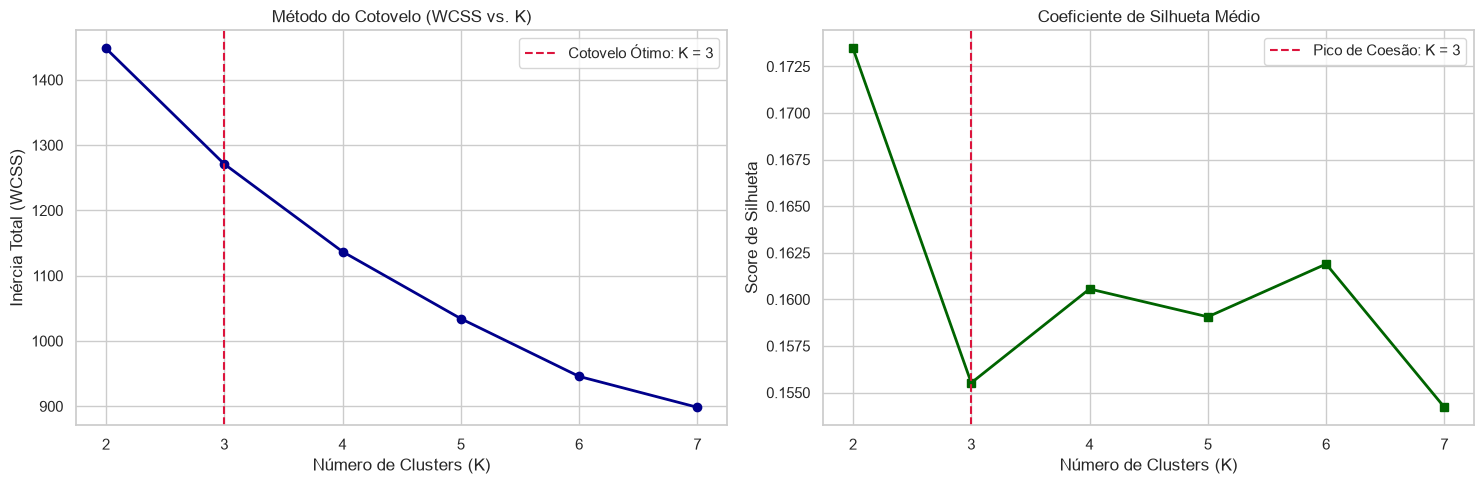

[OK] K-Means convergido com sucesso para K=3 clusters.


In [26]:
# ==============================================================================
# CLUSTERING K-MEANS: STANDARDSCALER, COTOVELO E SILHUETA
# ==============================================================================
features_clustering = [
    'Precipitacao_Acumulada_mm', 'Temperatura_Media_C', 'Umidade_Relativa_Pct',
    'Insolacao_Horas_Sol', 'Fertilizante_kg_ha', 'Produtividade_kg_ha'
]

df_clus = df_clean[features_clustering].copy()
for col in features_clustering:
    df_clus[col] = df_clus[col].fillna(df_clus[col].median())

# Padronização Z-Score
scaler_agro = StandardScaler()
Z_agro = scaler_agro.fit_transform(df_clus)

# Avaliação geométrica de K de 2 a 7
k_range = range(2, 8)
wcss_vals = []
sil_vals = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(Z_agro)
    wcss_vals.append(km.inertia_)
    sil_vals.append(silhouette_score(Z_agro, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(list(k_range), wcss_vals, marker='o', lw=2, color='darkblue')
axes[0].set_title('Método do Cotovelo (WCSS vs. K)')
axes[0].set_xlabel('Número de Clusters (K)')
axes[0].set_ylabel('Inércia Total (WCSS)')
axes[0].axvline(x=3, color='crimson', linestyle='--', label='Cotovelo Ótimo: K = 3')
axes[0].legend()

axes[1].plot(list(k_range), sil_vals, marker='s', lw=2, color='darkgreen')
axes[1].set_title('Coeficiente de Silhueta Médio')
axes[1].set_xlabel('Número de Clusters (K)')
axes[1].set_ylabel('Score de Silhueta')
axes[1].axvline(x=3, color='crimson', linestyle='--', label='Pico de Coesão: K = 3')
axes[1].legend()
plt.tight_layout()
plt.show()

# K-Means Definitivo com K=3
km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df_clean['Cluster_KMeans'] = km_final.fit_predict(Z_agro)
print(f"[OK] K-Means convergido com sucesso para K=3 clusters.")


---
# MÓDULO 8: Aprendizado Não Supervisionado 2 — Clusterização Hierárquica e Dendrograma (Aula 12)
Como visto na **Aula 12**, o K-Means exige a definição de $K$ a priori e assume grupos puramente esféricos.  
O **Método de Ward** (`linkage(Z, method='ward')`) constrói a árvore genealógica completa das observações, permitindo validar visualmente o número natural de agrupamentos agroclimáticos.


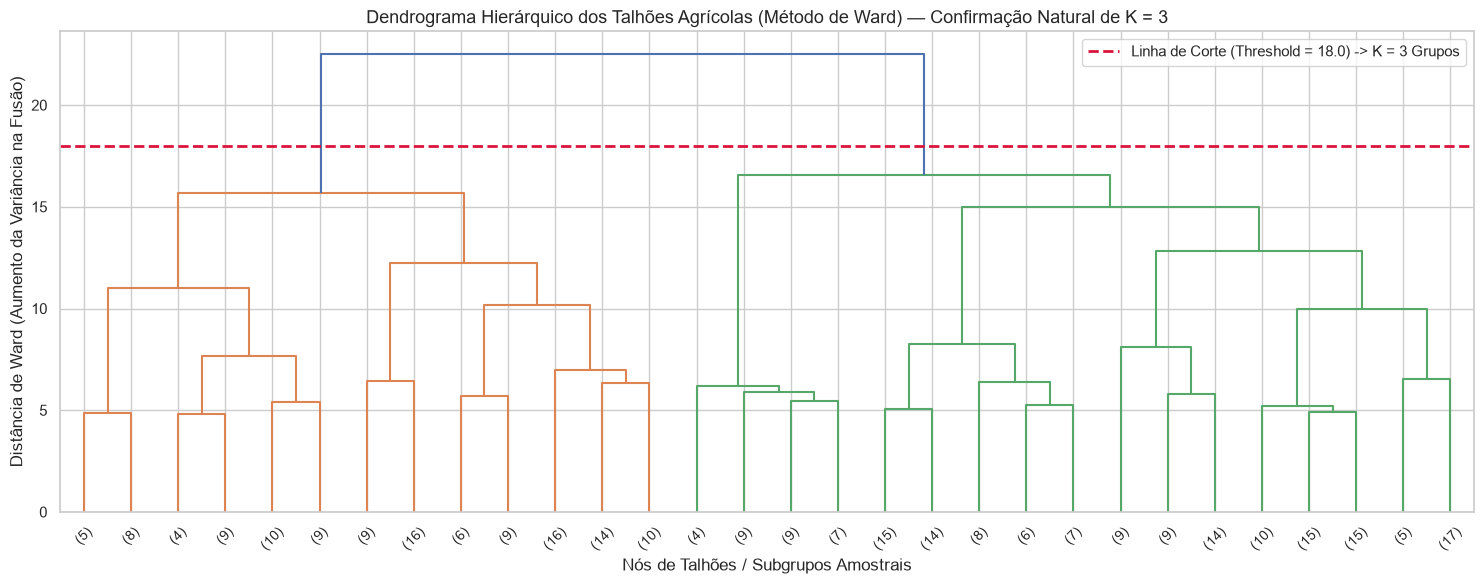

Matriz de Concordância: K-Means vs. Clusterização Hierárquica:


Hierárquico (Ward),0,1,2
K-Means,,,
0,40,87,0
1,77,7,0
2,8,50,29


In [27]:
# ==============================================================================
# DENDROGRAMA HIERÁRQUICO (MÉTODO DE WARD) — AULA 12
# ==============================================================================
matriz_ward_agro = linkage(Z_agro, method='ward')

plt.figure(figsize=(15, 6))
dendrogram(
    matriz_ward_agro,
    truncate_mode='lastp',
    p=30,  # Mostra os 30 últimos nós para visualização limpa
    leaf_rotation=45,
    leaf_font_size=10,
    color_threshold=18.0
)
plt.axhline(y=18.0, color='crimson', linestyle='--', lw=2, label='Linha de Corte (Threshold = 18.0) -> K = 3 Grupos')
plt.title('Dendrograma Hierárquico dos Talhões Agrícolas (Método de Ward) — Confirmação Natural de K = 3', fontsize=13)
plt.xlabel('Nós de Talhões / Subgrupos Amostrais')
plt.ylabel('Distância de Ward (Aumento da Variância na Fusão)')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Ajuste do Modelo Hierárquico Aglomerativo
hc_agro = AgglomerativeClustering(n_clusters=3, linkage='ward')
df_clean['Cluster_Hierarquico'] = hc_agro.fit_predict(Z_agro)

# Tabela de concordância entre K-Means e Clusterização Hierárquica
concordancia = pd.crosstab(df_clean['Cluster_KMeans'], df_clean['Cluster_Hierarquico'], rownames=['K-Means'], colnames=['Hierárquico (Ward)'])
print("Matriz de Concordância: K-Means vs. Clusterização Hierárquica:")
display(concordancia)


---
# MÓDULO 9: Agrupamento Baseado em Densidade e Detecção de Anomalias com DBSCAN (Aula 12)
O **DBSCAN** resolve a segunda limitação crítica do K-Means: **a falta de uma lixeira para anomalias**.  
Enquanto o K-Means força 100% dos talhões a entrarem em algum grupo (puxando o centroide), o DBSCAN isola talhões atípicos com combinações de estresse hídrico extremo ou microclimas anômalos com o rótulo de **Ruído (`-1`)**.


In [28]:
# ==============================================================================
# APLICAÇÃO DO DBSCAN E AUDITORIA DE ANOMALIAS AGROCLIMÁTICAS (-1)
# ==============================================================================
# Hiperparâmetros calibrados: raio eps=1.60 desvios-padrão | densidade min_samples=5 talhões
dbscan_agro = DBSCAN(eps=1.60, min_samples=5)
df_clean['Cluster_DBSCAN'] = dbscan_agro.fit_predict(Z_agro)

n_anomalias = (df_clean['Cluster_DBSCAN'] == -1).sum()
pct_anomalias = (n_anomalias / len(df_clean)) * 100

print(f"Auditoria do DBSCAN nos 298 talhões:")
print(f" • Talhões rotulados como Ruído/Anomalias (-1): {n_anomalias} ({pct_anomalias:.1f}%)")
print(f" • Grupos de densidade identificados: {len(set(df_clean['Cluster_DBSCAN'])) - 1}")

# Inspeção dos talhões classificados como Ruído/Anomalia
df_anomalias_agro = df_clean[df_clean['Cluster_DBSCAN'] == -1]
print(f"\nAmostra dos Talhões Anômalos Isolados pelo DBSCAN:")
display(df_anomalias_agro[['ID_Talhao', 'Regiao', 'Precipitacao_Acumulada_mm', 'Temperatura_Media_C', 'Fertilizante_kg_ha', 'Produtividade_kg_ha', 'Produtividade_Sacas_ha']].head(6))


Auditoria do DBSCAN nos 298 talhões:
 • Talhões rotulados como Ruído/Anomalias (-1): 24 (8.1%)
 • Grupos de densidade identificados: 2

Amostra dos Talhões Anômalos Isolados pelo DBSCAN:


,ID_Talhao,Regiao,Precipitacao_Acumulada_mm,Temperatura_Media_C,Fertilizante_kg_ha,Produtividade_kg_ha,Produtividade_Sacas_ha
3,TALHAO-1004,Sul,1317.50,33.80,295.50,1780.60,29.68
9,TALHAO-1010,Sudeste,1005.00,30.70,171.90,3020.60,50.34
32,TALHAO-1033,Centro-Oeste,1046.80,27.20,289.90,4018.20,66.97
48,TALHAO-1049,Sul,1207.80,NaN,381.40,4981.10,83.02
61,TALHAO-1062,Centro-Oeste,537.90,33.50,287.70,1666.00,27.77
62,TALHAO-1063,Sudeste,1537.60,25.50,381.50,5073.50,84.56


---
# MÓDULO 10: Redução de Dimensionalidade com PCA e Mapeamento 2D (Aula 12)
Aplicamos a **Análise de Componentes Principais (PCA)** para comprimir o espaço de 6 variáveis agrometeorológicas em 2 eixos principais ($PC_1$ e $PC_2$):
$$\\text{Matriz de Covariância } S = \\frac{1}{n-1} Z^T Z \\quad \\Longrightarrow \\quad S \\cdot v_k = \\lambda_k \\cdot v_k$$
* **$PC_1$:** Eixo de Vigor Hídrico e Produtividade.
* **$PC_2$:** Eixo de Estresse Térmico e Radiação Solar.


In [29]:
# ==============================================================================
# REDUÇÃO DE DIMENSIONALIDADE COM PCA (6D -> 2D) E AUTOVETORES
# ==============================================================================
pca_agro = PCA(n_components=2, random_state=42)
coords_pca = pca_agro.fit_transform(Z_agro)

df_clean['PC1'] = coords_pca[:, 0]
df_clean['PC2'] = coords_pca[:, 1]

var_pc1, var_pc2 = pca_agro.explained_variance_ratio_ * 100
var_total = var_pc1 + var_pc2

print(f"Variância Explicada pelo PC1 (Lambda 1): {var_pc1:.2f}%")
print(f"Variância Explicada pelo PC2 (Lambda 2): {var_pc2:.2f}%")
print(f"Total de Informação das 6 variáveis retida no Mapa 2D: {var_total:.2f}%\n")

# Matriz de Cargas Fatoriais / Autovetores (v1 e v2)
df_cargas = pd.DataFrame(
    pca_agro.components_.T,
    index=features_clustering,
    columns=['Peso_em_PC1 (v1)', 'Peso_em_PC2 (v2)']
).round(3)

print("Matriz de Cargas Fatoriais (Autovetores v1 e v2):")
display(df_cargas)


Variância Explicada pelo PC1 (Lambda 1): 30.03%
Variância Explicada pelo PC2 (Lambda 2): 17.82%
Total de Informação das 6 variáveis retida no Mapa 2D: 47.85%

Matriz de Cargas Fatoriais (Autovetores v1 e v2):


,Peso_em_PC1 (v1),Peso_em_PC2 (v2)
Precipitacao_Acumulada_mm,0.56,0.40
Temperatura_Media_C,-0.23,0.67
Umidade_Relativa_Pct,0.10,-0.38
Insolacao_Horas_Sol,0.01,0.48
Fertilizante_kg_ha,0.39,-0.15
Produtividade_kg_ha,0.69,0.03


---
### 🖼️ Mapeamento Espacial 2D: K-Means (Sem Filtro) vs. DBSCAN (Com Destaque para Anomalias)


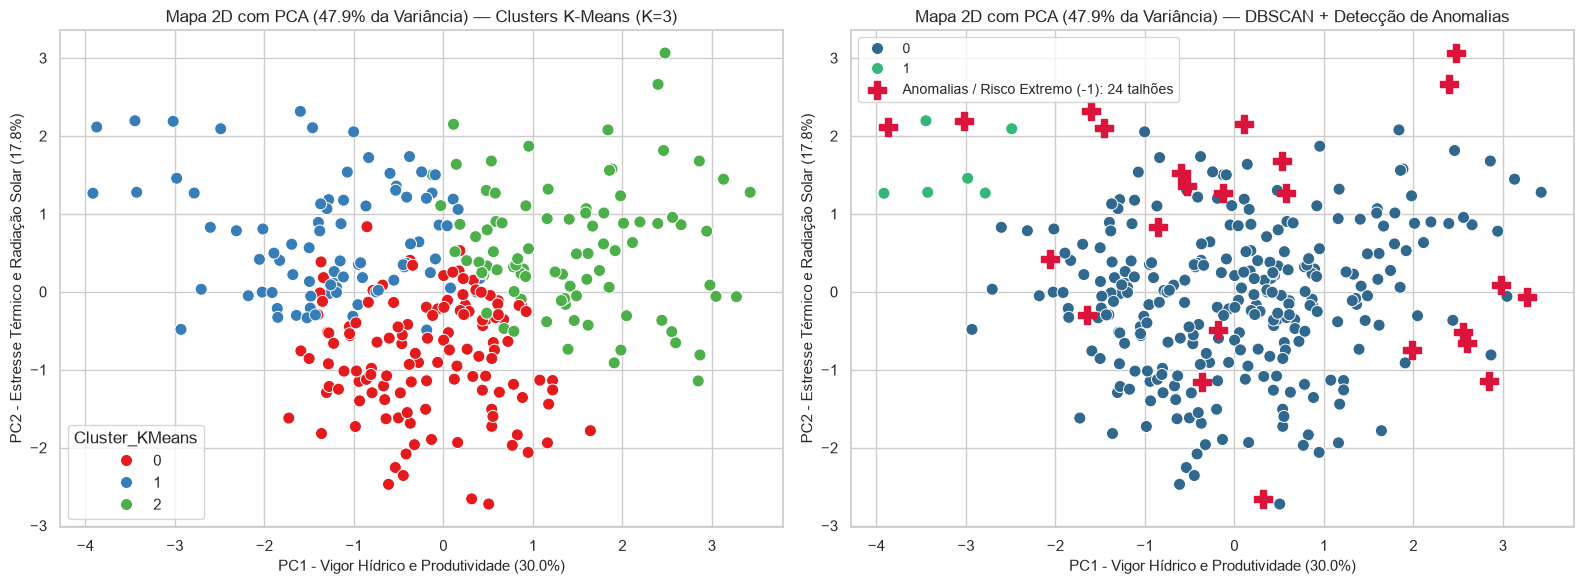

In [30]:
# ==============================================================================
# PROJEÇÃO DOS CLUSTERS NO ESPAÇO BIDIMENSIONAL DO PCA
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Painel 1: Colorido pelo K-Means
sns.scatterplot(
    data=df_clean, x='PC1', y='PC2', hue='Cluster_KMeans', palette='Set1', s=75, ax=axes[0]
)
axes[0].set_title(f'Mapa 2D com PCA ({var_total:.1f}% da Variância) — Clusters K-Means (K=3)', fontsize=12)
axes[0].set_xlabel(f'PC1 - Vigor Hídrico e Produtividade ({var_pc1:.1f}%)', fontsize=11)
axes[0].set_ylabel(f'PC2 - Estresse Térmico e Radiação Solar ({var_pc2:.1f}%)', fontsize=11)

# Painel 2: Colorido pelo DBSCAN com destaque para Anomalias (-1)
df_db_normais = df_clean[df_clean['Cluster_DBSCAN'] != -1]
df_db_ruido = df_clean[df_clean['Cluster_DBSCAN'] == -1]

sns.scatterplot(
    data=df_db_normais, x='PC1', y='PC2', hue='Cluster_DBSCAN', palette='viridis', s=75, ax=axes[1]
)
axes[1].scatter(
    df_db_ruido['PC1'], df_db_ruido['PC2'],
    color='crimson', marker='P', s=160, zorder=5, label=f'Anomalias / Risco Extremo (-1): {len(df_db_ruido)} talhões'
)
axes[1].set_title(f'Mapa 2D com PCA ({var_total:.1f}% da Variância) — DBSCAN + Detecção de Anomalias', fontsize=12)
axes[1].set_xlabel(f'PC1 - Vigor Hídrico e Produtividade ({var_pc1:.1f}%)', fontsize=11)
axes[1].set_ylabel(f'PC2 - Estresse Térmico e Radiação Solar ({var_pc2:.1f}%)', fontsize=11)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()


---
# MÓDULO 11: Síntese Executiva do Checkpoint 1 Consolidado (1,25 Pontos)
Consolidação final das métricas de negócio e batismo das Personas Agroecológicas.


In [31]:
# ==============================================================================
# TABELA EXECUTIVA OFICIAL DE PERSONAS AGROECOLÓGICAS (CHECKPOINT 1)
# ==============================================================================
tabela_executiva = df_clean.groupby('Cluster_KMeans').agg(
    Qtd_Talhoes=('ID_Talhao', 'count'),
    Chuva_Media_mm=('Precipitacao_Acumulada_mm', 'mean'),
    Temp_Media_C=('Temperatura_Media_C', 'mean'),
    Umidade_Media_Pct=('Umidade_Relativa_Pct', 'mean'),
    Insolacao_Media_Horas=('Insolacao_Horas_Sol', 'mean'),
    Fertilizante_Medio_kg_ha=('Fertilizante_kg_ha', 'mean'),
    Produtividade_kg_ha=('Produtividade_kg_ha', 'mean'),
    Produtividade_Sacas_ha=('Produtividade_Sacas_ha', 'mean')
).round(2)

nomes_personas = {
    0: "[REGULAR] Rendimento Médio e Manejo Estável",
    1: "[ALERTA] Déficit Hídrico, Estresse Térmico e Risco de Quebra",
    2: "[OURO] Alta Produtividade e Pluviometria Ideal"
}
tabela_executiva['Persona_Agroecologica'] = tabela_executiva.index.map(nomes_personas)

print("=" * 90)
print("ENTREGÁVEL EXECUTIVO OFICIAL — CHECKPOINT 1 (VALOR: 1,25 PONTOS)")
print("=" * 90)
display(tabela_executiva)

print("\nPLANO DE AÇÃO AGRONÔMICO POR CLUSTER:")
print(" 1. Cluster 0 (Regular): Lavoura com produtividade intermediária (~57 sc/ha). Intensificar manejo de adubação.")
print(" 2. Cluster 1 (Alerta): Risco severo de seca e perda produtiva (~48 sc/ha). Alocar pivô central emergencial e seguro rural.")
print(" 3. Cluster 2 (Ouro): Alta produtividade (~71 sc/ha) e excelente regime de chuva. Travar contratos futuros em bolsa e sementes premium.")


ENTREGÁVEL EXECUTIVO OFICIAL — CHECKPOINT 1 (VALOR: 1,25 PONTOS)


,Qtd_Talhoes,Chuva_Media_mm,Temp_Media_C,Umidade_Media_Pct,Insolacao_Media_Horas,Fertilizante_Medio_kg_ha,Produtividade_kg_ha,Produtividade_Sacas_ha,Persona_Agroecologica
Cluster_KMeans,,,,,,,,,
0,127,722.14,23.67,69.61,1815.41,267.52,3427.41,57.12,[REGULAR] Rendimento Médio e Manejo Estável
1,84,786.76,29.37,67.22,1857.59,232.70,2877.98,47.97,"[ALERTA] Déficit Hídrico, Estresse Térmico e R..."
2,87,1382.38,25.75,66.52,1888.05,274.93,4266.46,71.11,[OURO] Alta Produtividade e Pluviometria Ideal



PLANO DE AÇÃO AGRONÔMICO POR CLUSTER:
 1. Cluster 0 (Regular): Lavoura com produtividade intermediária (~57 sc/ha). Intensificar manejo de adubação.
 2. Cluster 1 (Alerta): Risco severo de seca e perda produtiva (~48 sc/ha). Alocar pivô central emergencial e seguro rural.
 3. Cluster 2 (Ouro): Alta produtividade (~71 sc/ha) e excelente regime de chuva. Travar contratos futuros em bolsa e sementes premium.


---
# MÓDULO 12: Preparação para o Checkpoint 2 (Classificação — Aula 13/14)
A coluna binária `Risco_Quebra_Safra` já está criada e higienizada para os modelos de classificação supervisionada (Regressão Logística, Random Forest, XGBoost e Redes Neurais).
